# Week 3. Time reversal

This notebook accompanies Chapter 4 of the notes. It follows the path from Langevin dynamics to diffusion
models.

1. Simulated annealing crosses barriers, but freezes the weights of the modes at the wrong values.
2. The Ornstein–Uhlenbeck (OU) process turns any data distribution into a Gaussian.
3. Its time reversal, with the exact score, turns the Gaussian back into the data, weights included.
4. Along the way, the score is a denoiser (Tweedie's formula).
5. With a learned score, this is a diffusion model.

Everything runs on a laptop CPU in about a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

rng = np.random.default_rng(2)
torch.manual_seed(2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Langevin, annealing and the reverse OU process on a mixture

The target is $q=0.8\,\mathcal N(-ae_1,s^2I_n)+0.2\,\mathcal N(ae_1,s^2I_n)$ in dimension $n=20$, with $s=0.35$. All three
samplers start from $\mathcal N(0,I_n)$, use Euler–Maruyama with step $10^{-3}$ and the *exact* scores, and we only plot the
first coordinate, the one that separates the modes.

- **Langevin.** $\mathrm dX=\nabla\log q(X)\,\mathrm dt+\sqrt2\,\mathrm dB$ up to time $20$.
- **Annealing towards temperature one.** $\mathrm dX=\beta(t)\nabla\log q(X)\,\mathrm dt+\sqrt2\,\mathrm dB$, where the inverse temperature
  $\beta(t)$ increases linearly from $0.05$ to $1$ on $[0,15]$, then stays at $1$ until time $20$.
- **Reverse OU.** $\mathrm dY_t=[Y_t+2s_{T-t}(Y_t)]\,\mathrm dt+\sqrt2\,\mathrm dB_t$ on $[0,T]$ with $T=5$, where $s_\tau$ is the score of the
  noised data $q_\tau$. For a Gaussian mixture, $q_\tau$ is again a Gaussian mixture, with means $e^{-\tau}(\pm ae_1)$ and
  component variance $e^{-2\tau}s^2+1-e^{-2\tau}$.

separation a = 1.0


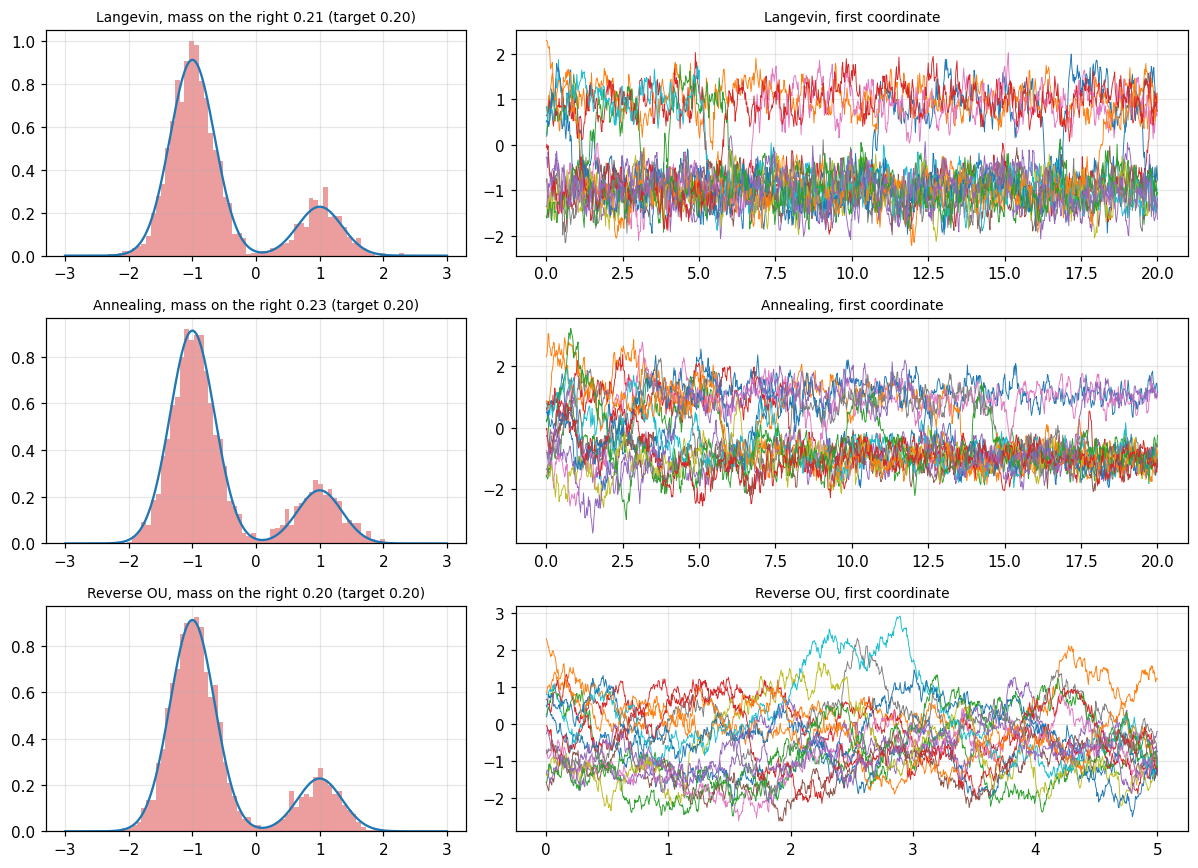

separation a = 2.5


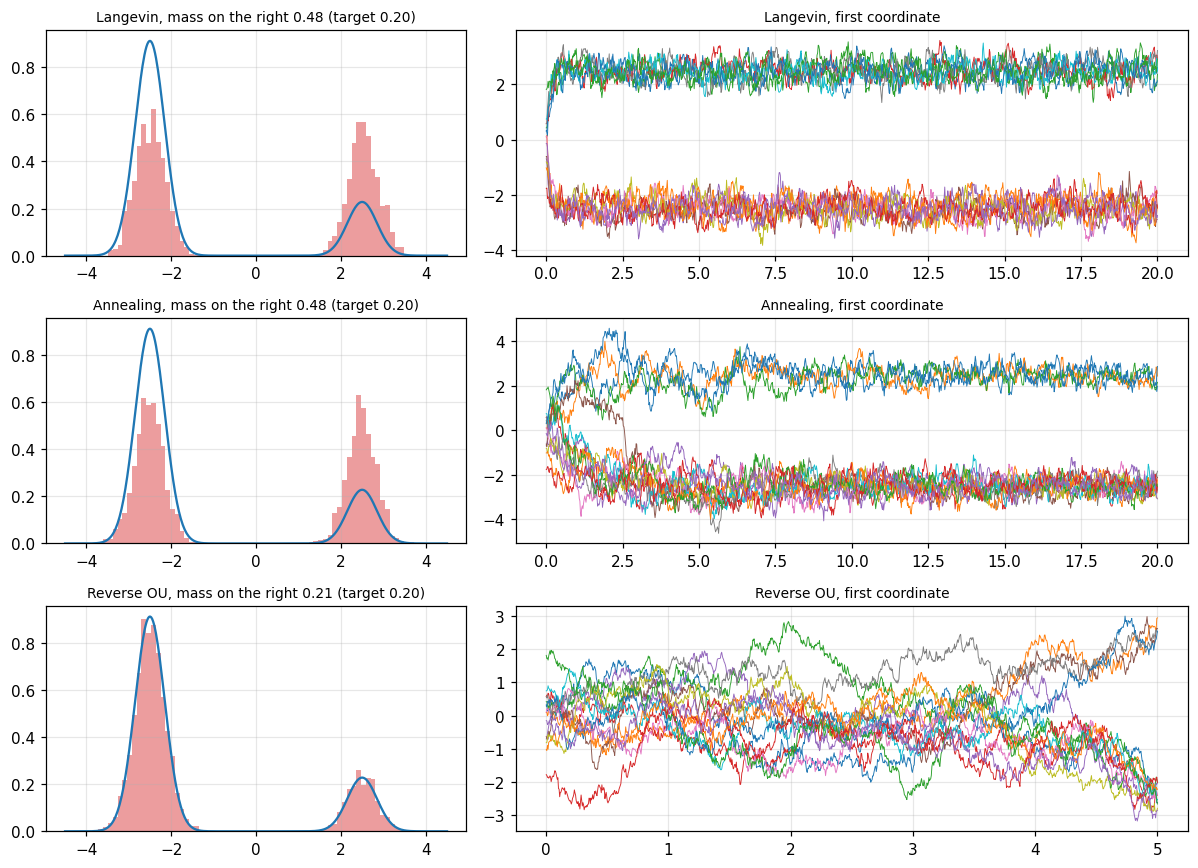

In [2]:
N_DIM, N_PART, W_LEFT, S, STEP = 20, 2000, 0.8, 0.35, 1e-3

def mixture_score(x, a, s2, shrink=1.0):
    # score of W_LEFT N(-shrink*a e1, s2 I) + (1-W_LEFT) N(shrink*a e1, s2 I)
    m = np.zeros(x.shape[1]); m[0] = shrink * a
    dl, dr = x + m, x - m
    log_l = np.log(W_LEFT) - 0.5 * (dl**2).sum(1) / s2
    log_r = np.log(1 - W_LEFT) - 0.5 * (dr**2).sum(1) / s2
    r_l = 1 / (1 + np.exp(np.clip(log_r - log_l, -50, 50)))
    return -(r_l[:, None] * dl + (1 - r_l)[:, None] * dr) / s2

def run_samplers(a, n_traj=15):
    x0 = rng.standard_normal((N_PART, N_DIM)); out = {}
    for name in ["Langevin", "Annealing"]:
        x = x0.copy(); traj = [x[:n_traj, 0].copy()]
        for k in range(int(20 / STEP)):
            beta = 1.0 if name == "Langevin" else 0.05 + 0.95 * min(k * STEP / 15, 1.0)
            x = x + STEP * beta * mixture_score(x, a, S**2) + np.sqrt(2 * STEP) * rng.standard_normal(x.shape)
            if k % 20 == 0: traj.append(x[:n_traj, 0].copy())
        out[name] = (x[:, 0], np.linspace(0, 20, len(traj)), np.array(traj))
    T = 5.0; y = x0.copy(); traj = [y[:n_traj, 0].copy()]
    for k in range(int(T / STEP)):
        tau = T - k * STEP
        v_tau = np.exp(-2 * tau) * S**2 + 1 - np.exp(-2 * tau)
        y = y + STEP * (y + 2 * mixture_score(y, a, v_tau, shrink=np.exp(-tau))) + np.sqrt(2 * STEP) * rng.standard_normal(y.shape)
        if k % 5 == 0: traj.append(y[:n_traj, 0].copy())
    out["Reverse OU"] = (y[:, 0], np.linspace(0, T, len(traj)), np.array(traj))
    return out

def plot_samplers(a, out):
    fig, ax = plt.subplots(3, 2, figsize=(11, 8), gridspec_kw={"width_ratios": [1, 1.6]})
    z = np.linspace(-a - 2, a + 2, 400)
    g = lambda m: np.exp(-0.5 * (z - m)**2 / S**2) / np.sqrt(2 * np.pi * S**2)
    for row, (name, (final, ts, traj)) in enumerate(out.items()):
        ax[row, 0].hist(final, bins=80, range=(z[0], z[-1]), density=True, alpha=0.45, color="tab:red")
        ax[row, 0].plot(z, W_LEFT * g(-a) + (1 - W_LEFT) * g(a))
        ax[row, 0].set_title(f"{name}, mass on the right {np.mean(final > 0):.2f} (target 0.20)", fontsize=9)
        ax[row, 1].plot(ts, traj, lw=0.6)
        ax[row, 1].set_title(f"{name}, first coordinate", fontsize=9)
    plt.tight_layout(); plt.show()

for a in [1.0, 2.5]:
    print(f"separation a = {a}")
    plot_samplers(a, run_samplers(a))

With moderate separation all three samplers find the right proportions. With well-separated modes,
Langevin dynamics keeps the proportions of its initialisation. Annealing crosses the barrier while the
temperature is high, but at high temperature the tempered target $q^\beta$ gives the two modes masses
proportional to $0.8^\beta$ and $0.2^\beta$, almost equal, and these proportions freeze when crossings stop. Only the reverse
OU process recovers the weight $0.2$. It never needs to cross a barrier, because the noised distributions
$q_\tau$ have overlapping modes, and their scores do carry the weights.

## 2. The OU process turns data into noise

The forward OU process $\mathrm d\bar X_\tau=-\bar X_\tau\,\mathrm d\tau+\sqrt2\,\mathrm dB_\tau$ has the explicit solution
$\bar X_\tau=e^{-\tau}\bar X_0+\sigma_\tau Z$ with $\sigma_\tau^2=1-e^{-2\tau}$. We watch the first coordinate of the mixture above, with $a=2.5$, being
noised.

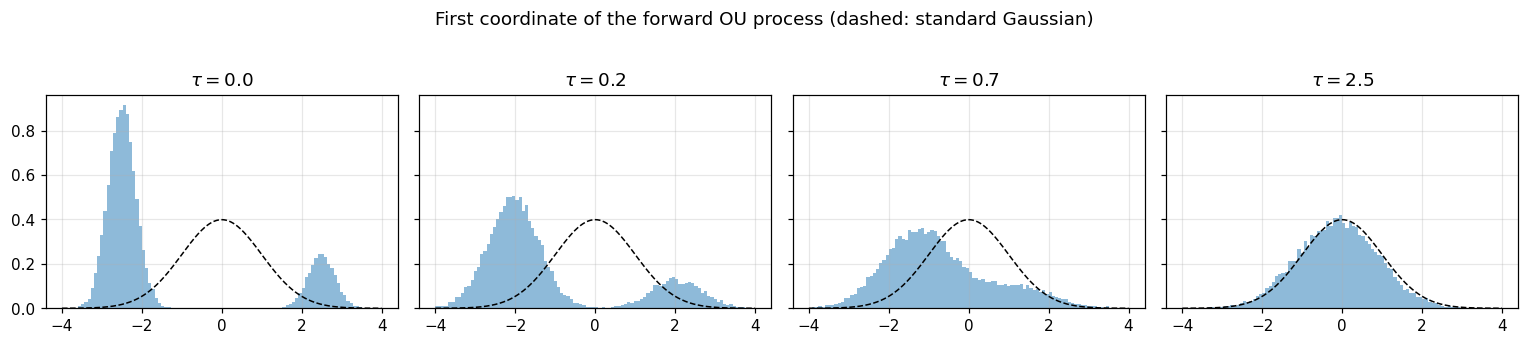

In [3]:
a = 2.5
idx = rng.random(20_000) < W_LEFT
x0 = rng.standard_normal((20_000, N_DIM)) * S
x0[:, 0] += np.where(idx, -a, a)
fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
z = np.linspace(-4, 4, 400)
for a_, tau in zip(ax, [0.0, 0.2, 0.7, 2.5]):
    xt = np.exp(-tau) * x0 + np.sqrt(1 - np.exp(-2 * tau)) * rng.standard_normal(x0.shape)
    a_.hist(xt[:, 0], bins=100, range=(-4, 4), density=True, alpha=0.5)
    a_.plot(z, np.exp(-z**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1)
    a_.set_title(rf"$\tau={tau}$")
plt.suptitle("First coordinate of the forward OU process (dashed: standard Gaussian)", y=1.03)
plt.tight_layout(); plt.show()

At $\tau\approx2.5$ the two modes have merged and the law is close to $\gamma_n$, whatever the data. The bridge from data
to noise is explicit. The reverse direction is the hard one.

## 3. Time reversal with the exact score

For Gaussian data $q=\mathcal N(0,vI_n)$, the noised laws are $q_\tau=\mathcal N(0,\lambda_\tau I_n)$ with $\lambda_\tau=e^{-2\tau}v+\sigma_\tau^2$, and the score is
$s_\tau(x)=-x/\lambda_\tau$. Starting from $q_T$ and running the reverse SDE with this score should give a process with law
$q_{T-t}$ at every time $t$. We check this numerically for a narrow distribution, $v=0.05$, in dimension $n=100$.

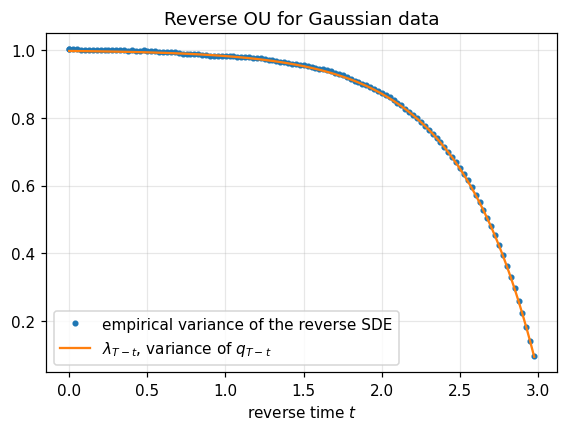

In [4]:
n, v, T, h = 100, 0.05, 3.0, 1e-3
lam = lambda tau: np.exp(-2 * tau) * v + 1 - np.exp(-2 * tau)
y = np.sqrt(lam(T)) * rng.standard_normal((2000, n))
ts, var_emp = [0.0], [y.var()]
for k in range(int(T / h) - 1):            # stop one step before T, where lambda is smallest
    tau = T - k * h
    y = y + h * (y - 2 * y / lam(tau)) + np.sqrt(2 * h) * rng.standard_normal(y.shape)
    if k % 25 == 0:
        ts.append((k + 1) * h); var_emp.append(y.var())
ts = np.array(ts)
plt.figure(figsize=(6, 4))
plt.plot(ts, var_emp, ".", label="empirical variance of the reverse SDE")
plt.plot(ts, lam(T - ts), label=r"$\lambda_{T-t}$, variance of $q_{T-t}$")
plt.xlabel("reverse time $t$"); plt.legend(); plt.title("Reverse OU for Gaussian data")
plt.show()

The reverse SDE contracts the variance from about $1$ to $v$. The drift $x+2s_{T-t}(x)$ expands, through the term $x$,
but the score term pulls the particles together more strongly near the end, where $\lambda_{T-t}$ is small. As
$v\to0$ the score $-x/\lambda_\tau$ blows up near $\tau=0$, which is why in practice one stops slightly before $T$.

## 4. The score is a denoiser

By Tweedie's formula along the OU process,
$$
  \mathbb E[\bar X_0\mid\bar X_\tau=x]=e^{\tau}\bigl(x+\sigma_\tau^2s_\tau(x)\bigr).
$$
For the mixture, we plot the first coordinate of this posterior mean along the line $x=x_1e_1$, for several noise
levels.

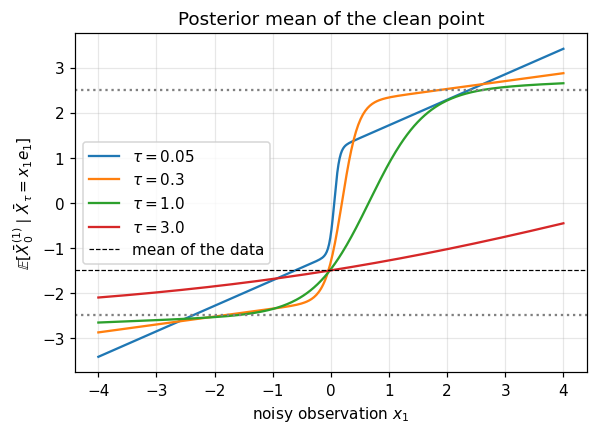

In [5]:
xs = np.linspace(-4, 4, 400)
pts = np.zeros((len(xs), N_DIM)); pts[:, 0] = xs
plt.figure(figsize=(6, 4))
for tau in [0.05, 0.3, 1.0, 3.0]:
    v_tau = np.exp(-2 * tau) * S**2 + 1 - np.exp(-2 * tau)
    score = mixture_score(pts, a, v_tau, shrink=np.exp(-tau))
    post_mean = np.exp(tau) * (pts + (1 - np.exp(-2 * tau)) * score)
    plt.plot(xs, post_mean[:, 0], label=rf"$\tau={tau}$")
plt.axhline(-a, c="gray", ls=":"); plt.axhline(a, c="gray", ls=":")
plt.axhline(W_LEFT * (-a) + (1 - W_LEFT) * a, c="k", ls="--", lw=0.8, label="mean of the data")
plt.xlabel(r"noisy observation $x_1$"); plt.ylabel(r"$\mathbb{E}[\bar X_0^{(1)}\mid \bar X_\tau=x_1e_1]$"); plt.legend()
plt.title("Posterior mean of the clean point")
plt.show()

At small noise the denoiser returns essentially the observation itself, except near the boundary between the
modes, where it jumps from one mode to the other. At intermediate noise it pulls each observation towards the
nearest mode. At large noise it returns almost the mean of the data, since the observation carries little
information. Learning the scores of all the $q_\tau$ is the
same as learning to denoise at every noise level.

## 5. A diffusion model with a learned score

We now forget the exact score. From $10\,000$ samples of the mixture we train a small network $\hat s(x,\tau)$ by denoising
score matching along the OU process, minimising
$$
  \mathbb E_{\tau,\bar X_0,Z}\Bigl|\sigma_\tau\,\hat s(e^{-\tau}\bar X_0+\sigma_\tau Z,\tau)+Z\Bigr|^2
$$
with $\tau$ uniform on $[\delta,T]$. The factor $\sigma_\tau$ is the usual weighting, which makes all noise levels equally important.
Then we run the reverse SDE from $\mathcal N(0,I_n)$ with the learned score. We use dimension $n=10$ and separation $a=2.5$.

In [6]:
n, T, delta = 10, 4.0, 0.01
data = rng.standard_normal((10_000, n)) * S
data[:, 0] += np.where(rng.random(10_000) < W_LEFT, -a, a)
data_t = torch.tensor(data, dtype=torch.float32)

class ScoreNet(nn.Module):
    def __init__(self, n, width=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n + 16, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(), nn.Linear(width, n))
        self.freqs = torch.exp(torch.linspace(0, np.log(100), 8))
    def forward(self, x, tau):
        emb = torch.cat([torch.sin(tau[:, None] * self.freqs), torch.cos(tau[:, None] * self.freqs)], dim=1)
        sigma = torch.sqrt(1 - torch.exp(-2 * tau))[:, None]
        return -self.net(torch.cat([x, emb], dim=1)) / sigma     # predict the noise, return the score

model = ScoreNet(n)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for step in range(6000):
    x0 = data_t[torch.randint(0, len(data_t), (512,))]
    tau = delta + (T - delta) * torch.rand(512)
    z = torch.randn_like(x0)
    sigma = torch.sqrt(1 - torch.exp(-2 * tau))[:, None]
    xt = torch.exp(-tau)[:, None] * x0 + sigma * z
    loss = ((sigma * model(xt, tau) + z)**2).sum(1).mean()
    opt.zero_grad(); loss.backward(); opt.step()
print(f"final training loss {loss.item():.3f}")

final training loss 0.457


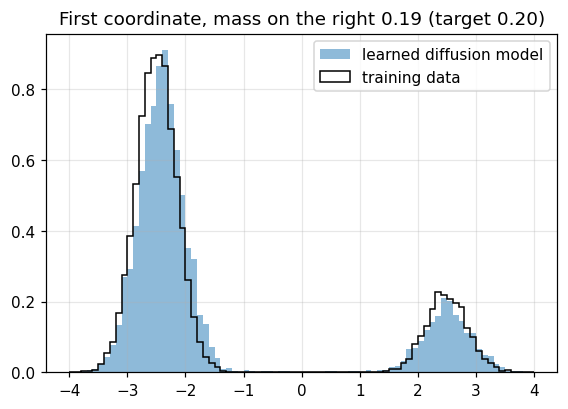

mean of the other coordinates   -0.007 (target 0)
std of the other coordinates    0.388 (target about 0.35)


In [7]:
@torch.no_grad()
def reverse_sample(score_fn, M=4000, K=500):
    # Euler-Maruyama for the reverse SDE on [0, T - delta], from N(0, I)
    y = torch.randn(M, n); ts = np.linspace(0, T - delta, K + 1)
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h = t1 - t0; tau = torch.full((M,), T - t0, dtype=torch.float32)
        y = y + h * (y + 2 * score_fn(y, tau)) + np.sqrt(2 * h) * torch.randn_like(y)
    return y.numpy()

samples = reverse_sample(model)
plt.figure(figsize=(6, 4))
plt.hist(samples[:, 0], bins=80, range=(-4, 4), density=True, alpha=0.5, label="learned diffusion model")
plt.hist(data[:, 0], bins=80, range=(-4, 4), density=True, histtype="step", color="k", label="training data")
plt.legend(); plt.title(f"First coordinate, mass on the right {np.mean(samples[:, 0] > 0):.2f} (target 0.20)")
plt.show()
print("mean of the other coordinates  ", np.round(samples[:, 1:].mean(), 3), "(target 0)")
print("std of the other coordinates   ", np.round(samples[:, 1:].std(), 3), f"(target about {S})")

The learned model recovers both modes with roughly the right weights, from samples alone and without any
normalising constant. The remaining errors come from the three approximations analysed in Week 4. The
initialisation uses $\mathcal N(0,I_n)$ instead of $q_T$, the score is learned, and time is discretised.

*Things to try.* Set $T=0.5$ and look at the initialisation error. Reduce the number of reverse steps $K$ to $20$.
Train for only $500$ steps and see which features of the data are learned first.